# skin — comp_group_id 결함 수정 후 재검증 (누수감사 후속)

**발견한 문제**: 직전 `skin_subgroup_leak_audit.ipynb`의 누수감사에서, production 659행(usable) 중 **83개 벡터그룹(276행, 약 42%)이 "완전히 같은 feature 벡터인데 서로 다른 `comp_group_id`"**를 갖고 있었습니다. 원인을 추적한 결과:

> **원본 544개 제형의 `comp_group_id`는 조성(성분) 기반 해시가 아니라 그냥 `formulation_id`를 복사한 값입니다.** (`skin_formulation_level_with_comp_group.csv`에서 `comp_group_id == formulation_id`인 행이 **97.2%**) 즉, 같은 활성성분 하나짜리 제형이 여러 제품명(= 다른 `formulation_id`)으로 등록돼 있어도, 지금까지 쓴 `StratifiedGroupKFold(groups=comp_group_id)`는 이걸 **다른 그룹으로 취급**해서 같은 조성이 train/test에 동시에 들어갈 수 있었습니다(=그룹 기반 누수 방지가 원본 데이터에서는 사실상 작동 안 함). 증강 118개는 반대로 진짜 조성 해시를 쓰고 있어서 문제 없습니다.

**이 노트북이 하는 일**: 원본·증강 전체에 대해 **조성 서명(해결된 성분 CASRN+함량 기반) 해시로 `comp_group_id`를 다시 계산**하고, 같은 CV 설정(StratifiedGroupKFold 5-fold×5seed)으로 `mid` 정책(659행) 16개 조합(4방식×2라벨×2모델)을 재실행해서, 지금까지 발표하려던 MCC 수치가 그룹핑 결함 때문에 부풀려져 있었는지 확인합니다.

## 0단계 — 데이터 로드 (직전 노트북과 동일 재구성 로직)

In [1]:
import hashlib
import re

import numpy as np
import pandas as pd

BASE = r"C:\Users\UserK\학술제\skin irritation"
SRC_B5 = r"C:\Users\UserK\OneDrive - 덕성여자대학교\문서\카카오톡 받은 파일\skin_irritation_최종후보.xlsx"

filt = pd.read_csv(rf"{BASE}\skin_filtered.csv")
labels = pd.read_csv(rf"{BASE}\skin_formulation_level_with_comp_group.csv")
desc_full = pd.read_csv(rf"{BASE}\casrn_descriptors_full.csv").set_index("casrn")
FEATURE_COLS = list(desc_full.columns)

known = filt.dropna(subset=["casrn"]).copy()
known = known.drop_duplicates(subset=["formulation_id", "casrn"], keep="first")
known["has_descriptor"] = known["casrn"].isin(desc_full.index)
known = known.rename(columns={"casrn": "key", "percent_active_ingredient": "pct"})
known_unified = known[["formulation_id", "key", "pct", "has_descriptor"]].copy()

vec = pd.read_csv(rf"{BASE}\skin_vectorized.csv", low_memory=False)
aug_meta = vec.loc[vec["formulation_id"].astype(str).str.startswith("AUG_"),
                    ["formulation_id", "final_label"]].copy()
aug_meta["formulation_id"] = aug_meta["formulation_id"].str.replace("AUG_", "", regex=False)

NUMBER = r"\d+(?:\.\d+)?"
RANGE_RE = re.compile(rf"^({NUMBER})[-~]({NUMBER})%?$")
NUM_RE = re.compile(rf"^({NUMBER})%?$")
OCR_RE = re.compile(rf"\(OCR for\s*({NUMBER})\s*%?\)")
UNRELIABLE_MARKERS = ["inconsistency", "garbled", "international units", "per mg of product"]
SUFFIXES = [" percent by weight", " percent", "% by weight", "% w/w", " w/w", "% a.i.", " a.i.", "%"]


def clean_text(text):
    cleaned = str(text).strip().replace(" ", "").replace(",", "").strip("*'")
    for suf in SUFFIXES:
        suf_clean = suf.replace(" ", "")
        if cleaned.lower().endswith(suf_clean.lower()):
            cleaned = cleaned[: -len(suf_clean)]
            break
    return cleaned.lstrip(".")


def parse_bounds(text):
    if pd.isna(text):
        return None, None
    raw = str(text).strip()
    if any(m in raw.lower() for m in UNRELIABLE_MARKERS):
        return None, None
    m = OCR_RE.search(raw)
    if m:
        v = float(m.group(1))
        return v, v
    cleaned = clean_text(raw)
    if cleaned.count(".") > 1:
        return None, None
    try:
        m = RANGE_RE.match(cleaned)
        if m:
            return float(m.group(1)), float(m.group(2))
        m = NUM_RE.match(cleaned if cleaned.endswith("%") else cleaned + "%")
        if m:
            v = float(m.group(1))
            return v, v
        if re.fullmatch(NUMBER, cleaned):
            v = float(cleaned)
            return v, v
    except ValueError:
        return None, None
    return None, None


def resolve_pct_mid(row):
    if pd.notna(row.get("정확값")):
        return float(row["정확값"])
    lo, hi = row.get("하한"), row.get("상한")
    if pd.notna(lo) and pd.notna(hi):
        return (float(lo) + float(hi)) / 2
    lo, hi = parse_bounds(row.get("함량_원문"))
    if lo is None:
        return np.nan
    return (lo + hi) / 2


B5_KEYS = ["v4:B5_003", "v4:B5_006", "v4:B5_009", "v4:B5_018", "v4:C011", "v4:C012", "v4:C016"]
all_aug_keys = aug_meta["formulation_id"].tolist()
v2v3_keys = [k for k in all_aug_keys if k.startswith("v2:") or k.startswith("v3:")]
v4_other_keys = [k for k in all_aug_keys if k.startswith("v4:") and k not in B5_KEYS]

comp1 = pd.read_excel(rf"{BASE}\skin_보강후보_통합.xlsx", sheet_name="성분함량")
comp1 = comp1[comp1["후보키"].isin(v2v3_keys)].copy()
comp1["key"] = comp1["CAS_원문"].fillna(comp1["성분명_원문"])

comp2 = pd.read_excel(rf"{BASE}\skin_보강후보_v4_신규.xlsx", sheet_name="성분함량")
comp2 = comp2[comp2["후보키"].isin(v4_other_keys)].copy()
comp2["key"] = comp2["CAS_원문"].fillna(comp2["성분명_원문"])

ing_rows = []
for comp in (comp1, comp2):
    for _, r in comp.iterrows():
        ing_rows.append({"formulation_id": r["후보키"], "key": r["key"], "pct": resolve_pct_mid(r)})

verif = pd.read_excel(SRC_B5, sheet_name="V4성분검증")
verif = verif[verif["후보키"].isin(B5_KEYS)].copy()
used = verif[verif["used"] == True].copy()  # noqa: E712
used["key"] = used["resolved_cas"].fillna(used["성분명_원문"])
for _, r in used.iterrows():
    ing_rows.append({"formulation_id": r["후보키"], "key": r["key"], "pct": float(r["parsed_exact_pct"])})

ing = pd.DataFrame(ing_rows)
ing["has_descriptor"] = ing["key"].isin(desc_full.index)
aug_unified_mid = ing[["formulation_id", "key", "pct", "has_descriptor"]].copy()

raw_all = pd.concat([known_unified, aug_unified_mid], ignore_index=True)  # mid 정책, 659행 전체 원자료
print("원자료 로드 완료:", len(raw_all), "행 /", raw_all["formulation_id"].nunique(), "제형")


원자료 로드 완료: 1231 행 / 662 제형


## 1단계 — 조성 서명 기반 `comp_group_id` 재계산 (원본+증강 통일된 규칙)

증강 파이프라인(`03_build_augmented_dataset.py` 등)이 이미 쓰고 있던 규칙을 원본에도 동일 적용합니다: **해결된(구조 확인된) 성분의 `casrn:함량(소수 1자리)` 서명을 정렬해서 합친 문자열의 MD5 해시**. 조성이 같으면(활성성분과 비율이 같으면) 원본이든 증강이든 같은 그룹이 됩니다.

In [2]:
def comp_group_from_raw(fid, grp):
    g_resolved = grp[grp["has_descriptor"]]
    if len(g_resolved) == 0:
        return f"UNRESOLVED_{fid}"
    sig = "|".join(sorted(f"{k}:{p:.1f}" for k, p in zip(g_resolved["key"], g_resolved["pct"]) if pd.notna(p)))
    if sig == "":
        return f"UNRESOLVED_{fid}"
    return "GRP_" + hashlib.md5(sig.encode()).hexdigest()[:12]


new_group = {fid: comp_group_from_raw(fid, grp) for fid, grp in raw_all.groupby("formulation_id")}
new_group_df = pd.Series(new_group, name="comp_group_id_fixed").rename_axis("formulation_id").reset_index()

n_formulations = len(new_group_df)
n_unique_groups = new_group_df["comp_group_id_fixed"].nunique()
print(f"제형 수: {n_formulations} / 재계산된 고유 조성그룹 수: {n_unique_groups}")
print(f"(참고: 기존 comp_group_id는 원본의 97.2%가 formulation_id를 그대로 복사한 값이라 "
      f"사실상 그룹핑이 거의 안 된 상태였음)")

group_sizes = new_group_df["comp_group_id_fixed"].value_counts()
print(f"\n2개 이상 제형이 묶인 조성그룹 수: {(group_sizes > 1).sum()} (총 {group_sizes[group_sizes > 1].sum()}개 제형이 여기 속함)")
print("가장 큰 그룹 top5:")
print(group_sizes.head(5))


제형 수: 662 / 재계산된 고유 조성그룹 수: 635
(참고: 기존 comp_group_id는 원본의 97.2%가 formulation_id를 그대로 복사한 값이라 사실상 그룹핑이 거의 안 된 상태였음)

2개 이상 제형이 묶인 조성그룹 수: 26 (총 53개 제형이 여기 속함)
가장 큰 그룹 top5:
comp_group_id_fixed
GRP_fb2c85c4a71e    3
GRP_50abac0d5f43    2
GRP_2aa151f19798    2
GRP_1c3b7171c14f    2
GRP_13eef4bde4ea    2
Name: count, dtype: int64


## 2단계 — 같은 집계함수·CV 설정으로 16개 조합(4방식×2라벨×2모델, mid=659행) 재실행, 수정 전/후 비교

In [3]:
combined_labels_fixed = pd.concat(
    [labels[["formulation_id", "final_label"]], aug_meta], ignore_index=True
).merge(new_group_df, on="formulation_id", how="left")
combined_labels_fixed = combined_labels_fixed.rename(columns={"comp_group_id_fixed": "comp_group_id"})


def aggregate_group(g_resolved, method):
    d = desc_full.loc[g_resolved["key"]].values
    pct = g_resolved["pct"].fillna(1.0).values
    if pct.sum() == 0:
        pct = np.ones_like(pct)
    if method == "wmean":
        return (pct[:, None] * d).sum(axis=0) / pct.sum()
    elif method == "top":
        idx = int(np.argmax(pct))
        return d[idx]
    elif method == "max":
        return d.max(axis=0)
    elif method == "min":
        return d.min(axis=0)
    else:
        raise ValueError(method)


def build_final_fixed(method):
    rows = []
    for fid, grp in raw_all.groupby("formulation_id"):
        g_resolved = grp[grp["has_descriptor"]]
        if len(g_resolved) > 0:
            v = aggregate_group(g_resolved, method)
            row = {"formulation_id": fid, **dict(zip(FEATURE_COLS, v))}
        else:
            row = {"formulation_id": fid, **{c: np.nan for c in FEATURE_COLS}}
        rows.append(row)
    agg = pd.DataFrame(rows)
    comp_count = raw_all.groupby("formulation_id")["key"].nunique().rename("comp_count").reset_index()
    out = agg.merge(comp_count, on="formulation_id", how="left")
    out = out.merge(combined_labels_fixed, on="formulation_id", how="left", validate="one_to_one")
    out["binary_label_A"] = out["final_label"].map(lambda x: 1 if x in (1, 2) else 0)
    out["binary_label_B"] = out["final_label"].map(lambda x: 1 if x in (1, 2, 3) else 0)
    return out


METHODS = ["wmean", "top", "max", "min"]
finals_fixed = {m: build_final_fixed(m) for m in METHODS}
n_ok = finals_fixed["wmean"][FEATURE_COLS].notna().all(axis=1).sum()
print(f"659행 중 usable(feature 전부 존재): {n_ok}행")

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef, confusion_matrix

MODELS = {
    "ExtraTrees": lambda seed: ExtraTreesClassifier(
        n_estimators=500, class_weight="balanced", min_samples_leaf=2, n_jobs=-1, random_state=seed
    ),
    "RandomForest": lambda seed: RandomForestClassifier(
        n_estimators=500, class_weight="balanced_subsample", min_samples_leaf=2, n_jobs=-1, random_state=seed
    ),
}


def grouped_cv(df, feature_cols, label_col, model_name, n_splits=5, seeds=range(5)):
    ok = df[feature_cols].notna().all(axis=1).values
    X = df.loc[ok, feature_cols].values
    y = df.loc[ok, label_col].values
    g = df.loc[ok, "comp_group_id"].astype(str).values

    rows = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=s)
        oof = np.zeros(len(y))
        for tr, te in cv.split(X, y, g):
            assert set(g[tr]).isdisjoint(g[te]), "그룹 누수 발생"
            m = MODELS[model_name](s).fit(X[tr], y[tr])
            oof[te] = m.predict_proba(X[te])[:, 1]
        pred05 = (oof >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred05).ravel()
        rows.append({
            "seed": s, "roc_auc": roc_auc_score(y, oof), "pr_auc": average_precision_score(y, oof),
            "mcc": matthews_corrcoef(y, pred05),
            "sensitivity": tp / (tp + fn) if (tp + fn) > 0 else np.nan,
            "specificity": tn / (tn + fp) if (tn + fp) > 0 else np.nan,
        })
    return pd.DataFrame(rows), int(ok.sum()), int(y.sum())


fixed_results = []
for label_name, label_col in [("A", "binary_label_A"), ("B", "binary_label_B")]:
    for model_name in MODELS:
        for m in METHODS:
            r, n_used, n_pos = grouped_cv(finals_fixed[m], FEATURE_COLS, label_col, model_name)
            fixed_results.append({
                "label": label_name, "model": model_name, "method": m, "n_used": n_used, "n_pos": n_pos,
                "mcc_mean": r.mcc.mean(), "mcc_std": r.mcc.std(),
                "roc_auc_mean": r.roc_auc.mean(), "pr_auc_mean": r.pr_auc.mean(),
            })
            print(f"완료(그룹수정): label={label_name} model={model_name} method={m}")

fixed_table = pd.DataFrame(fixed_results)
fixed_table.to_csv(rf"{BASE}\skin_aggregation_fixed_grouping_results.csv", index=False, encoding="utf-8-sig")
print("저장:", rf"{BASE}\skin_aggregation_fixed_grouping_results.csv")


659행 중 usable(feature 전부 존재): 646행


완료(그룹수정): label=A model=ExtraTrees method=wmean


완료(그룹수정): label=A model=ExtraTrees method=top


완료(그룹수정): label=A model=ExtraTrees method=max


완료(그룹수정): label=A model=ExtraTrees method=min


완료(그룹수정): label=A model=RandomForest method=wmean


... (7 outputs left out)

완료(그룹수정): label=B model=RandomForest method=wmean


완료(그룹수정): label=B model=RandomForest method=top


완료(그룹수정): label=B model=RandomForest method=max


완료(그룹수정): label=B model=RandomForest method=min
저장: C:\Users\UserK\학술제\skin irritation\skin_aggregation_fixed_grouping_results.csv


## 3단계 — 그룹핑 수정 전(결함 있음) vs 수정 후 MCC 비교

In [4]:
old_table = pd.read_csv(rf"{BASE}\skin_aggregation_range_policy_full_results.csv")
old_mid = old_table[old_table.policy == "mid"][["label", "model", "method", "mcc_mean", "mcc_std"]]
old_mid = old_mid.rename(columns={"mcc_mean": "mcc_mean_old_grouping", "mcc_std": "mcc_std_old_grouping"})

cmp_df = fixed_table[["label", "model", "method", "mcc_mean", "mcc_std"]].rename(
    columns={"mcc_mean": "mcc_mean_fixed_grouping", "mcc_std": "mcc_std_fixed_grouping"}
).merge(old_mid, on=["label", "model", "method"])
cmp_df["변화(수정후-수정전)"] = cmp_df["mcc_mean_fixed_grouping"] - cmp_df["mcc_mean_old_grouping"]
pd.set_option("display.width", 150)
print(cmp_df.round(3).to_string(index=False))

print()
print("=== 팀 목표 조합 B/ExtraTrees 요약 ===")
sub = cmp_df[(cmp_df.label == "B") & (cmp_df.model == "ExtraTrees")].sort_values("mcc_mean_fixed_grouping", ascending=False)
print(sub.round(3).to_string(index=False))
print()
print("=== 참고 조합 A/RandomForest 요약 ===")
sub2 = cmp_df[(cmp_df.label == "A") & (cmp_df.model == "RandomForest")].sort_values("mcc_mean_fixed_grouping", ascending=False)
print(sub2.round(3).to_string(index=False))


label        model method  mcc_mean_fixed_grouping  mcc_std_fixed_grouping  mcc_mean_old_grouping  mcc_std_old_grouping  변화(수정후-수정전)
    A   ExtraTrees  wmean                    0.184                   0.039                  0.158                 0.050        0.026
    A   ExtraTrees    top                    0.174                   0.039                  0.150                 0.026        0.025
    A   ExtraTrees    max                    0.175                   0.009                  0.154                 0.056        0.021
    A   ExtraTrees    min                    0.189                   0.026                  0.178                 0.028        0.011
    A RandomForest  wmean                    0.198                   0.014                  0.153                 0.066        0.044
    A RandomForest    top                    0.253                   0.059                  0.222                 0.024        0.031
    A RandomForest    max                    0.242                   

## 4단계 — 시각화

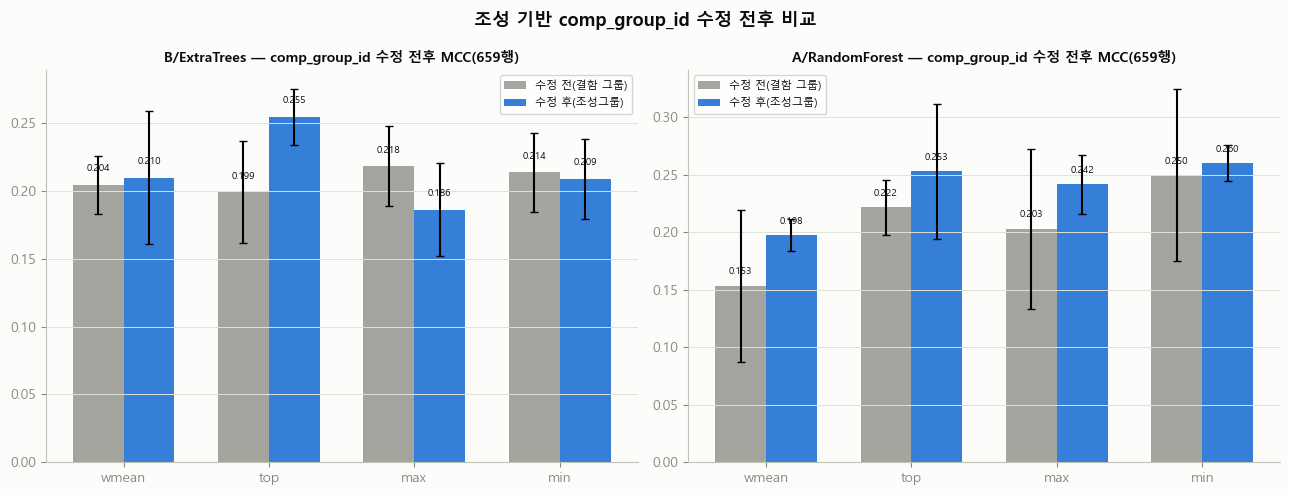

In [5]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

_font_path = r"C:\Windows\Fonts\malgun.ttf"
fm.fontManager.addfont(_font_path)
plt.rcParams["font.family"] = fm.FontProperties(fname=_font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

SURFACE = "#fcfcfb"; INK = "#0b0b0b"; MUTED = "#898781"; GRID_C = "#e1e0d9"; BASE_C = "#c3c2b7"

fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor=SURFACE)
for ax, (label_name, model_name) in zip(axes, [("B", "ExtraTrees"), ("A", "RandomForest")]):
    ax.set_facecolor(SURFACE)
    sub = cmp_df[(cmp_df.label == label_name) & (cmp_df.model == model_name)].set_index("method").loc[METHODS]
    x = np.arange(len(METHODS))
    w = 0.35
    ax.bar(x - w / 2, sub["mcc_mean_old_grouping"], width=w, yerr=sub["mcc_std_old_grouping"],
           capsize=3, label="수정 전(결함 그룹)", color="#898781", alpha=0.75)
    ax.bar(x + w / 2, sub["mcc_mean_fixed_grouping"], width=w, yerr=sub["mcc_std_fixed_grouping"],
           capsize=3, label="수정 후(조성그룹)", color="#2a78d6", alpha=0.95)
    for i, mname in enumerate(METHODS):
        ax.text(i - w / 2, sub.loc[mname, "mcc_mean_old_grouping"] + 0.01, f"{sub.loc[mname, 'mcc_mean_old_grouping']:.3f}",
                ha="center", fontsize=7, color=INK)
        ax.text(i + w / 2, sub.loc[mname, "mcc_mean_fixed_grouping"] + 0.01, f"{sub.loc[mname, 'mcc_mean_fixed_grouping']:.3f}",
                ha="center", fontsize=7, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels(METHODS)
    ax.set_title(f"{label_name}/{model_name} — comp_group_id 수정 전후 MCC(659행)", fontsize=10, color=INK, fontweight="bold")
    ax.legend(fontsize=8)
    ax.tick_params(colors=MUTED)
    for s_ in ["top", "right"]:
        ax.spines[s_].set_visible(False)
    ax.spines["left"].set_color(BASE_C)
    ax.spines["bottom"].set_color(BASE_C)
    ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)

fig.suptitle("조성 기반 comp_group_id 수정 전후 비교", fontsize=13, color=INK, fontweight="bold")
plt.tight_layout()
plt.savefig(rf"{BASE}\skin_fixed_grouping_before_after.png", dpi=150, facecolor=SURFACE)
plt.show()


## 한계점

1. 조성 서명은 "해결된(구조 확인된) 성분"만 반영합니다 — has_descriptor==False인 미해결 성분의 함량비는 서명에 포함되지 않아, 아주 드물게 실제로는 다른 조성인데 같은 그룹으로 묶일 가능성이 이론상 남아 있습니다.
2. 이 수정은 skin 쪽에만 적용했습니다. production `skin_formulation_level_with_comp_group.csv`/`skin_vectorized.csv` 원본 파일 자체는 아직 고치지 않았습니다(이 노트북은 검증용 사본으로만 작업) — 팀 확인 후 원본 파일 수정 여부를 결정해야 합니다.
3. eye팀도 유사한 그룹 문제를 100% 해결했다고 주장하지 않습니다 — 이 수정 이후에도 외부검증 없이는 "완전히 누수 없음"을 증명하지 않습니다.
